# EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
games_df = pd.read_csv('../data/raw/games.csv')
turns_df = pd.read_csv('../data/raw/turns.csv')
train_df = pd.read_csv('../data/raw/train.csv')
test_df = pd.read_csv('../data/raw/test.csv')

print(f'Games shape: {games_df.shape}')
print(f'Turns shape: {turns_df.shape}')
print(f'Train shape: {train_df.shape}')
print(f'Test shape: {test_df.shape}')

Games shape: (72773, 12)
Turns shape: (2005498, 9)
Train shape: (100820, 4)
Test shape: (44726, 4)


## Missing Values

In [3]:
print(f'{'*' * 20} DATAFRAME INFO {'*' * 20}\n')
print(f'{'-' * 10}games_df{'-' * 10}')
print(games_df.info(),'\n')
print(f'{'-' * 10}turns_df{'-' * 10}')
print(turns_df.info(),'\n')
print(f'{'-' * 10}train_df{'-' * 10}')
print(train_df.info(),'\n')
print(f'{'-' * 10}test_df{'-' * 10}')
print(f'test_df:\n {test_df.info()}\n')


******************** DATAFRAME INFO ********************

----------games_df----------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72773 entries, 0 to 72772
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   game_id                72773 non-null  int64  
 1   first                  72773 non-null  object 
 2   time_control_name      72773 non-null  object 
 3   game_end_reason        72773 non-null  object 
 4   winner                 72773 non-null  int64  
 5   created_at             72773 non-null  object 
 6   lexicon                72773 non-null  object 
 7   initial_time_seconds   72773 non-null  int64  
 8   increment_seconds      72773 non-null  int64  
 9   rating_mode            72773 non-null  object 
 10  max_overtime_minutes   72773 non-null  int64  
 11  game_duration_seconds  72773 non-null  float64
dtypes: float64(1), int64(5), object(6)
memory usage: 6.7+ MB
None 

-------

In [4]:
bots = ['BetterBot', 'STEEBot', 'HastyBot']

test_df_turns = test_df.merge(
    turns_df,
    on=['game_id', 'nickname'],
    how='left'
)
test_df_turns[~test_df_turns['nickname'].isin(bots)]

,game_id,nickname,score_x,rating,turn_number,rack,location,move,points,score_y,turn_type
0,2,Super,488,NaN,1,AFINRTV,8D,FAINT,24,24,Play
1,2,Super,488,NaN,3,AAERTVW,F10,WAVER,34,58,Play
2,2,Super,488,NaN,5,AABEFTY,15G,FY,44,102,Play
3,2,Super,488,NaN,7,AABCDET,K10,BEAD,33,135,Play
4,2,Super,488,NaN,9,ACEGIST,L6,CAGIEST,94,229,Play
...,...,...,...,...,...,...,...,...,...,...,...
614204,72769,browndav,384,NaN,25,?EEENNT,10A,ENtENTE,66,335,Play
614205,72769,browndav,384,NaN,27,OORTVWY,D2,VOW,32,367,Play
614206,72769,browndav,384,NaN,29,ORTY,B5,TYRO,19,386,Play
614207,72769,browndav,384,NaN,30,NaN,NaN,(CT),8,394,End


In [5]:
print(f'Percentage of missing rating values in test_df: {test_df["rating"].isnull().mean() * 100:.2f}%')

Percentage of missing rating values in test_df: 50.00%


In [6]:
print(f"{'*' * 20}STATISTICS (Numerical){'*' * 20}")
games_df.describe()

********************STATISTICS (Numerical)********************


,game_id,winner,initial_time_seconds,increment_seconds,max_overtime_minutes,game_duration_seconds
count,72773.000000,72773.000000,72773.000000,72773.00000,72773.000000,72773.000000
mean,36387.000000,0.350734,1198.034230,0.22856,2.143707,484.069347
std,21007.899907,0.484859,713.185219,2.54802,2.989853,333.563128
min,1.000000,-1.000000,15.000000,0.00000,0.000000,7.962989
25%,18194.000000,0.000000,900.000000,0.00000,1.000000,250.172459
50%,36387.000000,0.000000,1200.000000,0.00000,1.000000,399.834150
75%,54580.000000,1.000000,1200.000000,0.00000,1.000000,633.424285
max,72773.000000,1.000000,3600.000000,60.00000,10.000000,4444.821645


In [7]:
train_df.describe()

,game_id,score,rating
count,100820.000000,100820.000000,100820.000000
mean,36367.328605,399.029022,1875.592938
std,21020.288705,75.184778,231.791016
min,1.000000,-64.000000,1033.000000
25%,18139.000000,352.000000,1664.000000
50%,36339.500000,398.000000,1907.000000
75%,54625.000000,445.000000,2060.000000
max,72773.000000,1132.000000,2510.000000


In [8]:
print("--- STATISTICS (Categorical) ---")
games_df.describe(include=['object'])

--- STATISTICS (Categorical) ---


,first,time_control_name,game_end_reason,created_at,lexicon,rating_mode
count,72773,72773,72773,72773,72773,72773
unique,1314,4,4,72194,4,2
top,STEEBot,regular,STANDARD,2022-09-20 15:59:19,CSW21,RATED
freq,12210,60282,67987,3,44594,54076


In [9]:
train_df.describe(include=['object'])

,nickname
count,100820
unique,1031
top,HastyBot
freq,17346


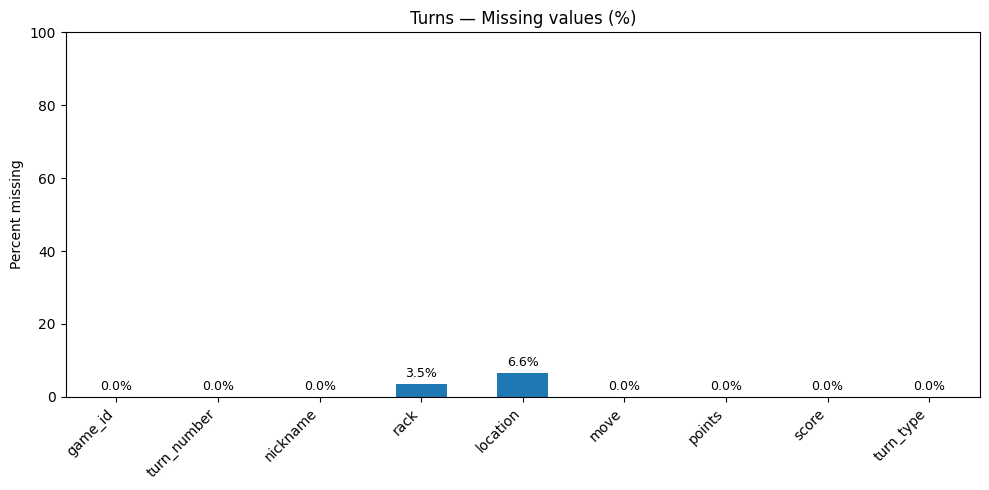

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
missing_pct = turns_df.isnull().mean() * 100
missing_pct.plot.bar(ax=ax, color='tab:blue')
ax.set_title('Turns — Missing values (%)')
ax.set_ylabel('Percent missing')
ax.set_ylim(0, max(100, missing_pct.max() + 5))
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(p.get_x() + p.get_width() / 2, height),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [11]:
rack_na_types = set(turns_df.loc[turns_df['rack'].isna(), 'turn_type'])
location_na_types = set(turns_df.loc[turns_df['location'].isna(), 'turn_type'])

print(f"Turn types with missing rack: {rack_na_types}")
print(f"Turn types with missing location: {location_na_types}")
print(f"Turn types with missing rack or location: {rack_na_types.union(location_na_types)}")

Turn types with missing rack: {'Challenge', 'Timeout', 'End'}
Turn types with missing location: {'Exchange', 'End', 'Pass', 'Six-Zero Rule', 'Timeout', 'Challenge'}
Turn types with missing rack or location: {'Exchange', 'End', 'Pass', 'Six-Zero Rule', 'Timeout', 'Challenge'}


### Missing Values Overview:
The missing values in the datasets make sense given the context of the game:
- In the `test` dataset, the missing values are just the rating we need to predict. 
- In the `turns` dataset, the missing values are:
    - `rack` and `location` which can be NA only if:
        1. The game ended.
        2. The player exchanged tiles instead of playing a word.
        3. The player passed their turn.
        4. The player was timed out.
        5. The Six-Zero rule was applied.
        6. The player challenged the previous player's word.

In [12]:
from sklearn.impute import SimpleImputer
def impute_missing_with_empty_string(df, column_name):
    imputer = SimpleImputer(strategy='constant', fill_value='')
    df[[column_name]] = imputer.fit_transform(df[[column_name]])
    return df
turns_df = impute_missing_with_empty_string(turns_df, 'rack')
turns_df = impute_missing_with_empty_string(turns_df, 'location')


## Distributions and Relationships

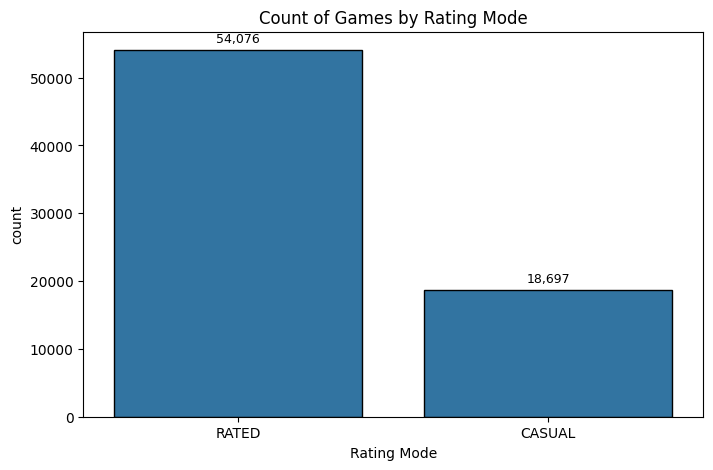

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
rating_mode_order = games_df['rating_mode'].value_counts().index
sns.countplot(data=games_df, x='rating_mode', order=rating_mode_order, ax=ax,edgecolor='black')
ax.set_title('Count of Games by Rating Mode')
ax.set_xlabel('Rating Mode')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(p.get_height()):,}',
                xy=(p.get_x() + p.get_width() / 2, height),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)
plt.show()

In [14]:
train_merged_df = train_df.merge(games_df, on='game_id')
test_merged_df = test_df.merge(games_df, on='game_id')
train_merged_df.head(3)

,game_id,nickname,score,rating,first,time_control_name,game_end_reason,winner,created_at,lexicon,initial_time_seconds,increment_seconds,rating_mode,max_overtime_minutes,game_duration_seconds
0,1,BetterBot,335,1637,BetterBot,regular,STANDARD,1,2022-08-26 03:38:49,NWL20,1200,0,CASUAL,1,674.844274
1,1,stevy,429,1500,BetterBot,regular,STANDARD,1,2022-08-26 03:38:49,NWL20,1200,0,CASUAL,1,674.844274
2,3,davidavid,440,1811,BetterBot,regular,STANDARD,1,2022-09-04 08:04:27,CSW21,900,0,RATED,5,492.268262


<Axes: xlabel='rating', ylabel='Count'>

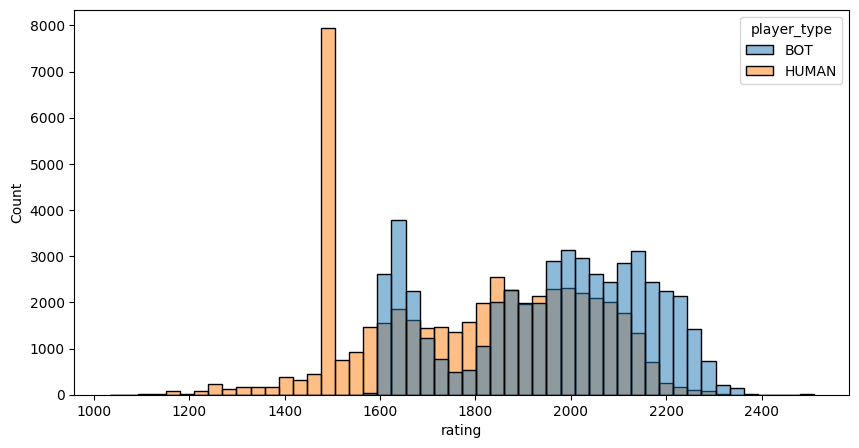

In [15]:
def add_player_type(df):
    bots = ['BetterBot', 'STEEBot', 'HastyBot']
    df["player_type"] = df["nickname"].apply(lambda name: "BOT" if name in bots else "HUMAN")
    return df
train_df = add_player_type(train_df)

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=train_df, x="rating", bins=50, hue="player_type")

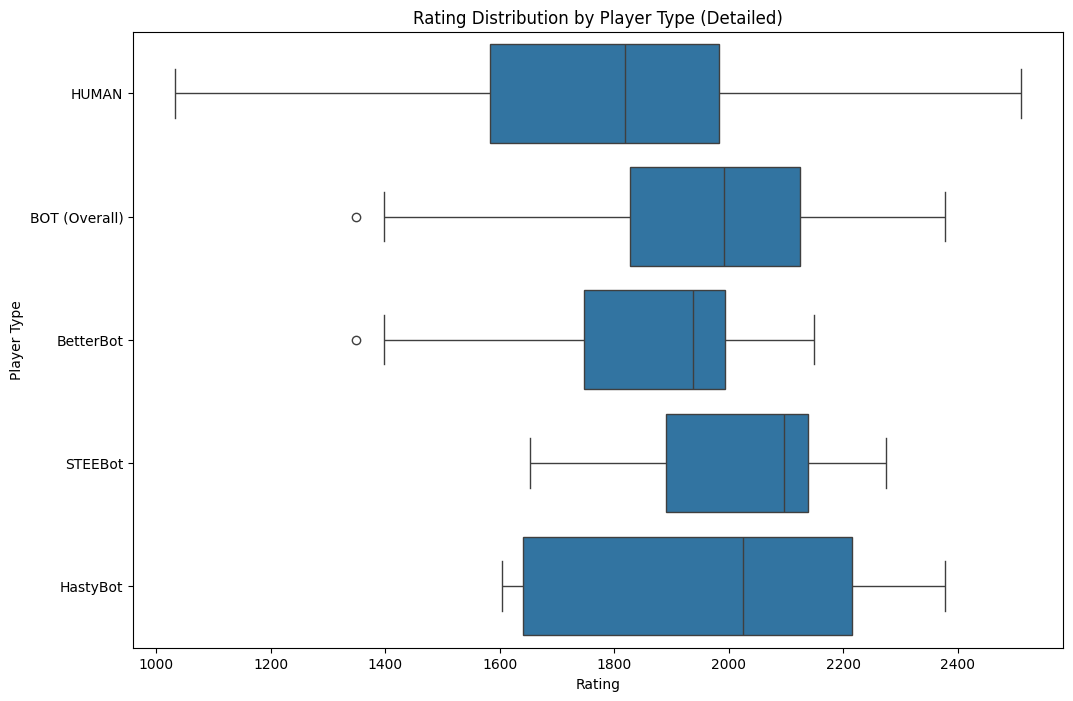

In [16]:
human_plot_df = train_df[train_df['player_type'] == 'HUMAN'].copy()
human_plot_df['plot_category'] = 'HUMAN'

bot_overall_df = train_df[train_df['player_type'] == 'BOT'].copy()
bot_overall_df['plot_category'] = 'BOT (Overall)'

bot_individual_df = train_df[train_df['player_type'] == 'BOT'].copy()
bot_individual_df['plot_category'] = bot_individual_df['nickname'] # This will be 'BetterBot', etc.

plot_df = pd.concat([human_plot_df, bot_overall_df, bot_individual_df])
plt.figure(figsize=(12, 8))

category_order = ['HUMAN', 'BOT (Overall)', 'BetterBot', 'STEEBot', 'HastyBot']
sns.boxplot(data=plot_df, x='rating', y='plot_category', order=category_order)
plt.title('Rating Distribution by Player Type (Detailed)')
plt.xlabel('Rating')
plt.ylabel('Player Type')
plt.show()

We can both in the histogram and the box plots that bots are generally higher-rated than human players, with tighter distributions.

 Interestingly, HastyBot has a wider distribution of ratings compared to BetterBot and STEEBot, and lower median rating than STEEBot, which in opposite to what we were told (BetterBot (beginner), STEEBot (intermediate), and HastyBot (advanced)). 

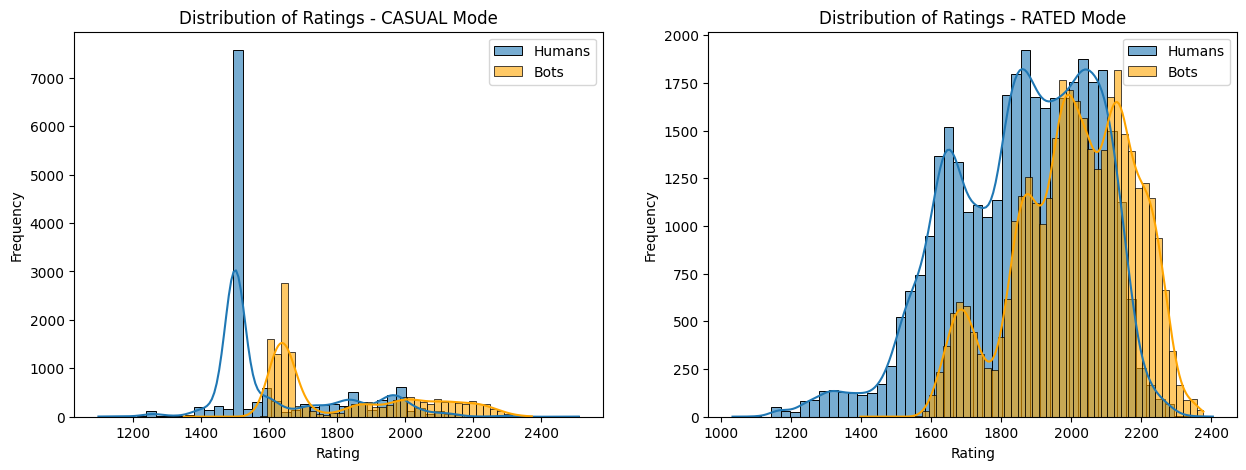

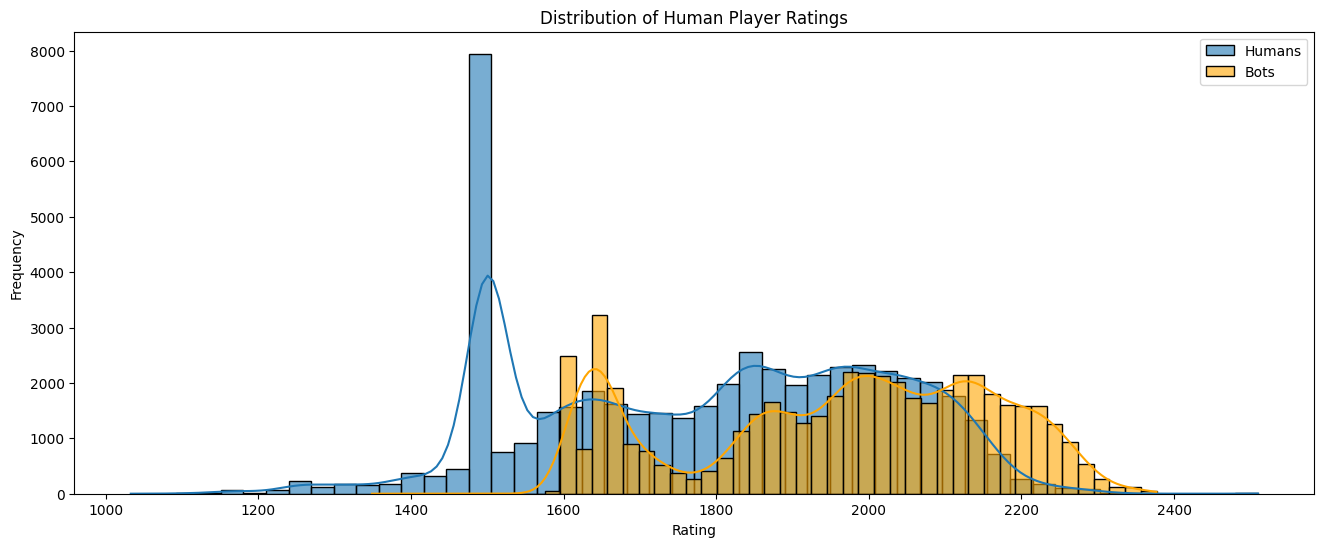

In [17]:
human_train_df = train_merged_df[~train_merged_df['nickname'].isin(bots)]
bots_train_df = train_merged_df[train_merged_df['nickname'].isin(bots)]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for i, mode in enumerate(human_train_df['rating_mode'].unique()):
    sns.histplot(human_train_df[human_train_df['rating_mode'] == mode]['rating'], kde=True, bins=50, ax=axes[i], label='Humans', alpha=0.6)
    sns.histplot(bots_train_df[bots_train_df['rating_mode'] == mode]['rating'], kde=True, bins=50, ax=axes[i], color='orange', label='Bots', alpha=0.6)
    axes[i].set_title(f'Distribution of Ratings - {mode} Mode')
    axes[i].set_xlabel('Rating')
    axes[i].set_ylabel('Frequency')
    axes[i].legend()
plt.show()

# plot overall rating distribution for human players
plt.figure(figsize=(16, 6))
sns.histplot(human_train_df['rating'], kde=True, bins=50, label='Humans', alpha=0.6)
sns.histplot(bots_train_df['rating'], kde=True, bins=50, label='Bots', color='orange', alpha=0.6)
plt.title('Distribution of Human Player Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.legend()
plt.show()

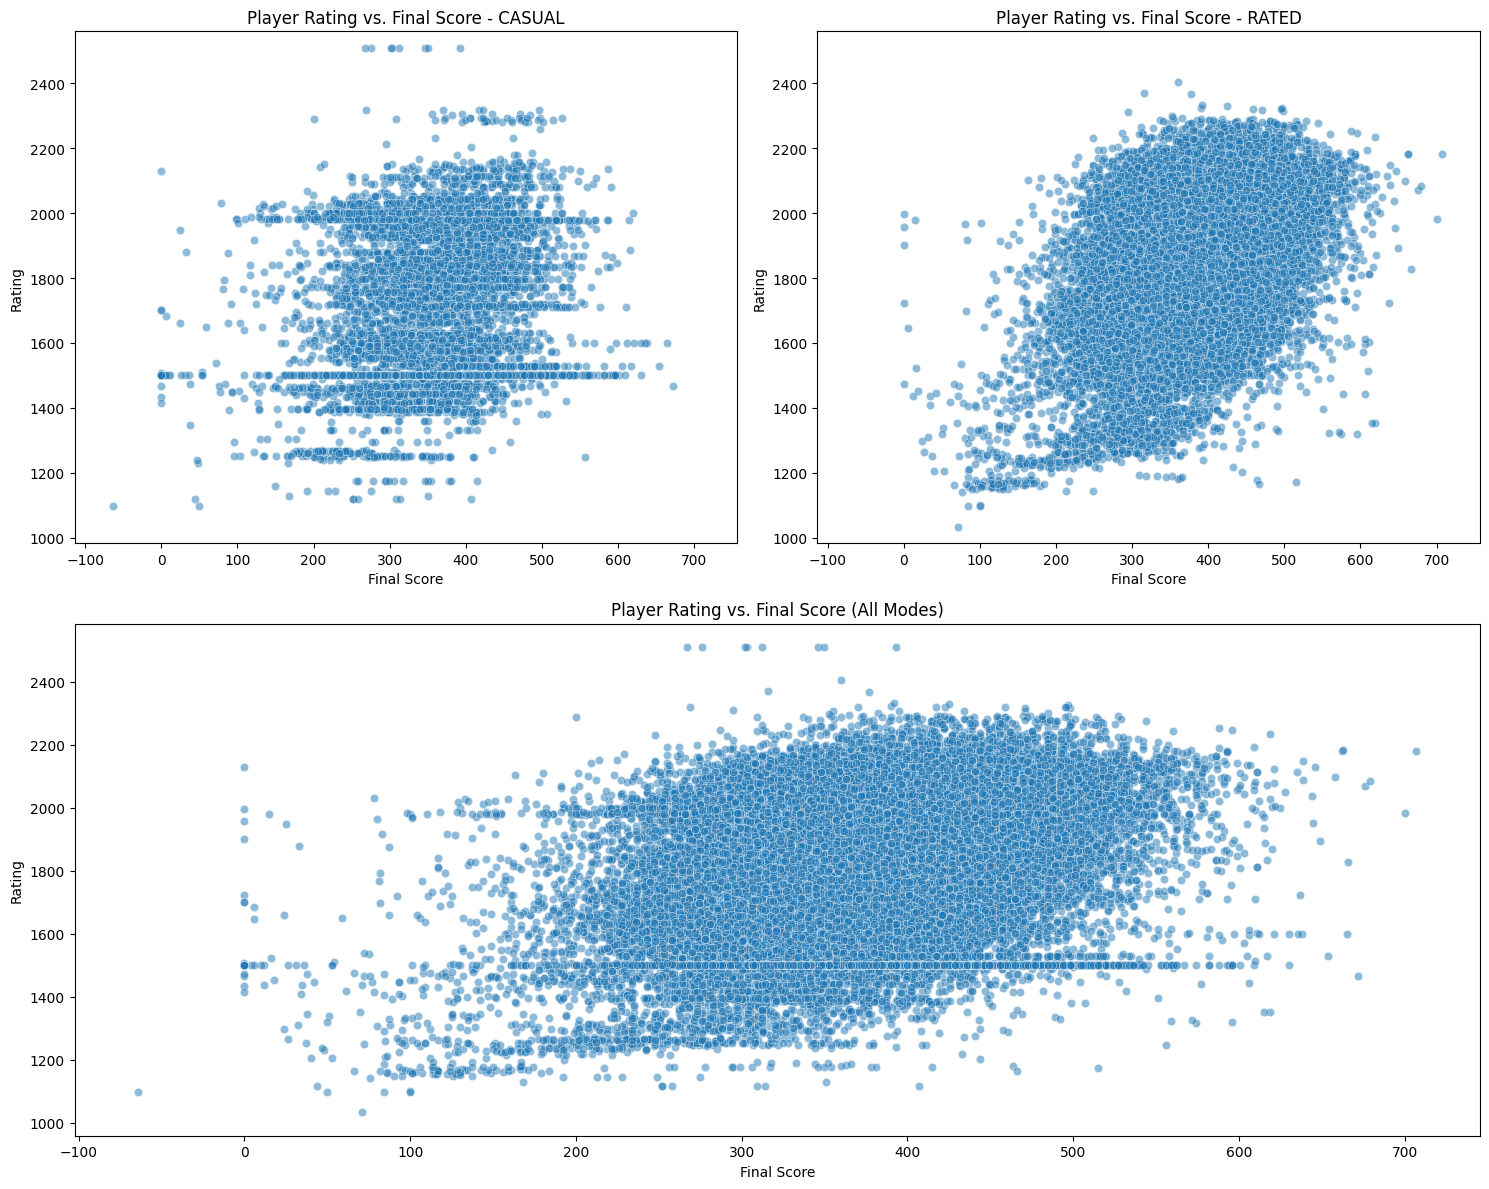

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for i, mode in enumerate(human_train_df['rating_mode'].unique()):
    sns.scatterplot(
        data=human_train_df[human_train_df['rating_mode'] == mode],
        x='score', y='rating', alpha=0.5, ax=axes[i]
    )
    axes[i].set_title(f'Player Rating vs. Final Score - {mode}')
    axes[i].set_xlabel('Final Score')
    axes[i].set_ylabel('Rating')
    # set consistent x and y limits
    axes[i].set_xlim(human_train_df['score'].min()-50, human_train_df['score'].max() +50)
    axes[i].set_ylim(human_train_df['rating'].min()-50, human_train_df['rating'].max() +50)

for j in [2, 3]:
    fig.delaxes(axes[j]) # deletes the bottom 2 axes

ax_big = fig.add_subplot(2, 1, 2)
sns.scatterplot(data=human_train_df, x='score', y='rating', alpha=0.5, ax=ax_big)
ax_big.set_title('Player Rating vs. Final Score (All Modes)')
ax_big.set_xlabel('Final Score')
ax_big.set_ylabel('Rating')

plt.tight_layout()
plt.show()


In [19]:
player_ratings = human_train_df.groupby('nickname', as_index=False).agg(
    all_ratings=('rating_mode', lambda x: x.unique().tolist())
)
only_casual_players_count = player_ratings[player_ratings['all_ratings'].apply(lambda x: x == ['CASUAL'])].shape[0]
total_players_count = player_ratings.shape[0]
print(f"Number of players who only played CASUAL games: {only_casual_players_count}/{total_players_count} which is {only_casual_players_count/total_players_count:.2%}")

Number of players who only played CASUAL games: 201/1028 which is 19.55%


In [20]:
def add_casual_only_flag(df):
    df = df.copy()
    player_has_only_casual = (
        df.groupby('nickname')['rating_mode']
        .apply(lambda x: set(x) == {'CASUAL'})
    )
    df['casual_only_player'] = df['nickname'].map(player_has_only_casual).astype(int)

    return df

add_casual_only_flag(train_merged_df).head()

,game_id,nickname,score,rating,first,time_control_name,game_end_reason,winner,created_at,lexicon,initial_time_seconds,increment_seconds,rating_mode,max_overtime_minutes,game_duration_seconds,casual_only_player
0,1,BetterBot,335,1637,BetterBot,regular,STANDARD,1,2022-08-26 03:38:49,NWL20,1200,0,CASUAL,1,674.844274,0
1,1,stevy,429,1500,BetterBot,regular,STANDARD,1,2022-08-26 03:38:49,NWL20,1200,0,CASUAL,1,674.844274,1
2,3,davidavid,440,1811,BetterBot,regular,STANDARD,1,2022-09-04 08:04:27,CSW21,900,0,RATED,5,492.268262,0
3,3,BetterBot,318,2071,BetterBot,regular,STANDARD,1,2022-09-04 08:04:27,CSW21,900,0,RATED,5,492.268262,0
4,4,Inandoutworker,119,1473,BetterBot,regular,RESIGNED,0,2022-09-12 02:36:19,CSW21,3600,0,CASUAL,1,350.861141,0


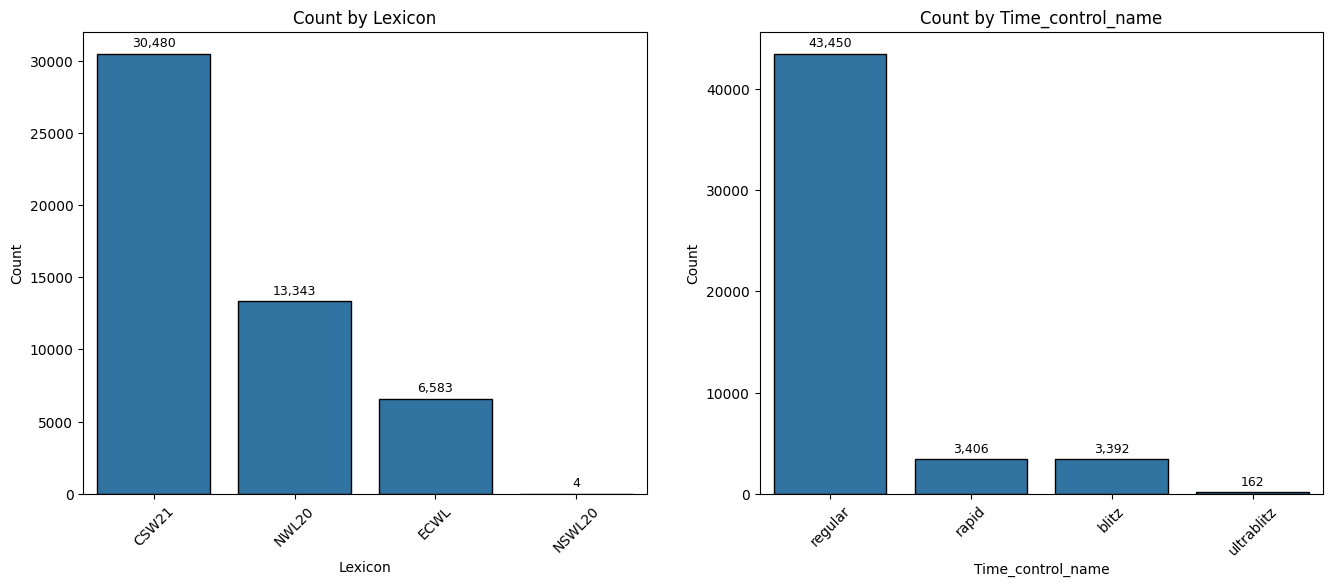

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

to_count = ['lexicon', 'time_control_name']
for i, name in enumerate(to_count):
    ax = axes[i]
    order = human_train_df[name].value_counts().index
    sns.countplot(data=human_train_df, x=name, order=order, ax=ax, edgecolor='black')
    ax.set_title(f'Count by {name.capitalize()}')
    ax.set_xlabel(name.capitalize())
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=45)
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

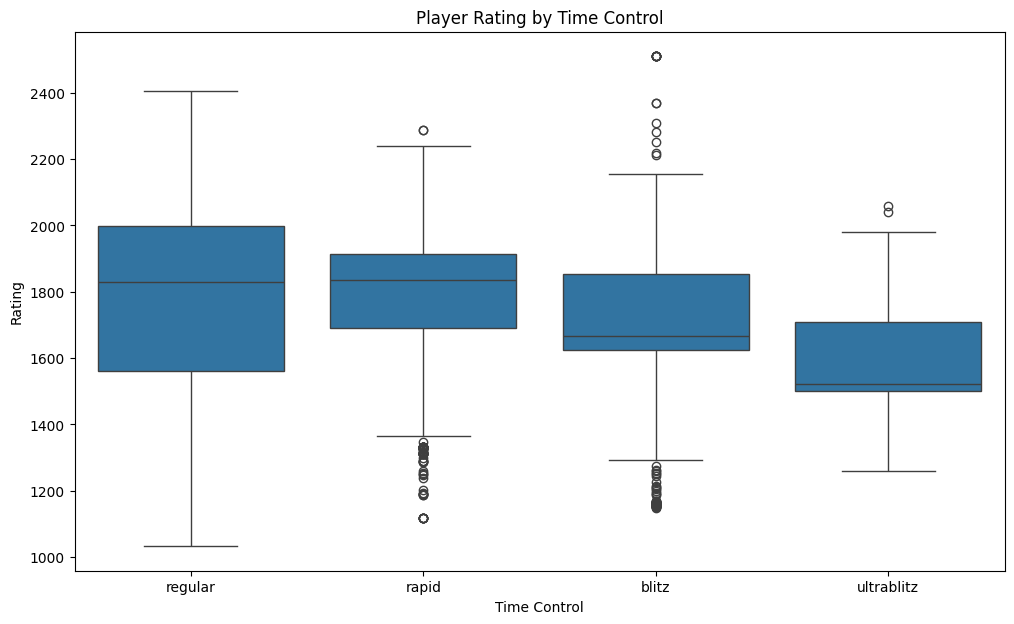

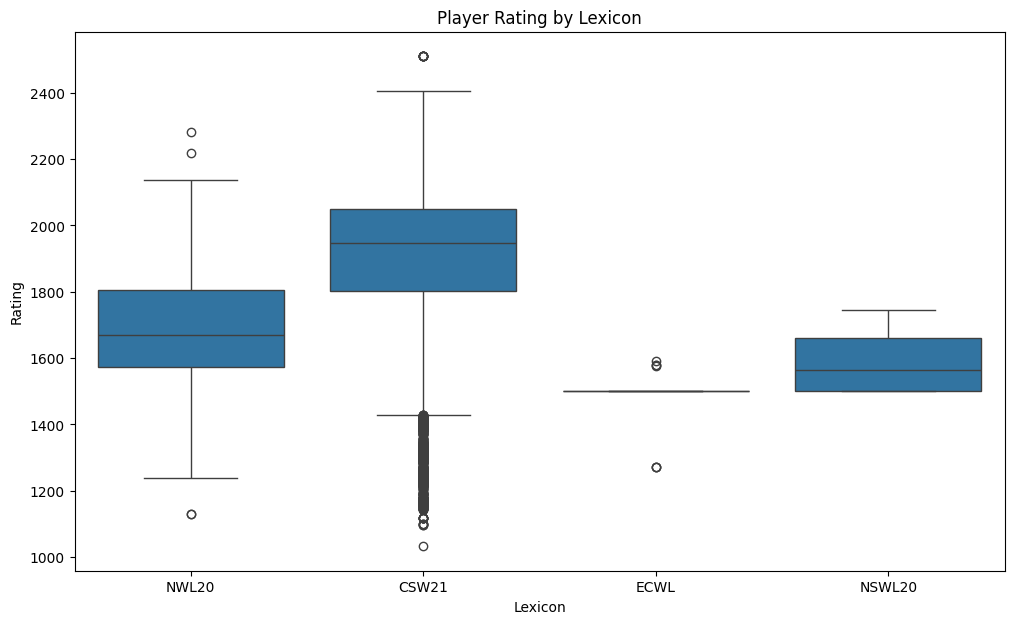

In [22]:
plt.figure(figsize=(12, 7))
sns.boxplot(data=human_train_df, x='time_control_name', y='rating')
plt.title('Player Rating by Time Control')
plt.xlabel('Time Control')
plt.ylabel('Rating')
plt.show()

plt.figure(figsize=(12, 7))
sns.boxplot(data=human_train_df, x='lexicon', y='rating')
plt.title('Player Rating by Lexicon')
plt.xlabel('Lexicon')
plt.ylabel('Rating')
plt.show()

In [23]:
lexicon_rating_mode_counts = human_train_df.groupby(['lexicon', 'rating_mode']).size().unstack()
lexicon_rating_mode_counts['CASUAL_percent'] = (lexicon_rating_mode_counts['CASUAL'] / lexicon_rating_mode_counts.sum(axis=1)) * 100
lexicon_rating_mode_counts

rating_mode,CASUAL,RATED,CASUAL_percent
lexicon,,,
CSW21,5047,25433,16.558399
ECWL,6579,4,99.939237
NSWL20,2,2,50.000000
NWL20,2746,10597,20.580079


In [24]:
lexicon_player_counts = human_train_df.groupby('lexicon')['nickname']
lexicon_player_counts.nunique()

lexicon
CSW21     819
ECWL        3
NSWL20      2
NWL20     236
Name: nickname, dtype: int64

In [25]:
player_ratings = human_train_df.groupby('nickname', as_index=False).agg(
    all_ratings=('rating_mode', lambda x: x.unique().tolist())
)
only_casual_ecwl_players = human_train_df[human_train_df['lexicon'] == 'ECWL']['nickname'].unique()
only_casual_ecwl_count = player_ratings[player_ratings['nickname'].isin(only_casual_ecwl_players) &
                                        player_ratings['all_ratings'].apply(lambda x: x == ['CASUAL'])].shape[0]
print(f"Number of ECWL players who only played CASUAL games: {only_casual_ecwl_count}/{len(only_casual_ecwl_players)} which is {only_casual_ecwl_count/len(only_casual_ecwl_players):.2%}") 

Number of ECWL players who only played CASUAL games: 2/3 which is 66.67%


### Lexicon and Rating Mode Analysis
- We can see that players who play regular or rapid games tend to have higher ratings than those who play blitz games, which in turn tend to have higher ratings than those who play ultrablitz games. I should not that the distribution of all ratings is pretty sparse.
- We can clearly that the median and IQR of player's ratings who play the CSW21 lexicon are higher than those who play any other lexicon.
- There are 2 anomalies in the box plots:
    1. The distribution of ratings for players using the ECWL lexicon is EXTREMELY tight. This is because, as can be seen in the tables above:
        - 99.93% of the games played with the ECWL lexicon are in CASUAL mode
        - There are only 3 unique players who played this mode
        - 2/3 of them play only CASUAL. 
        This makes the distribution very tight since most of the players dont even change their rating in the dataset
    2. The NSWL20 lexicon looks ok at first, but we can see that it has only 4 games played with it, with 2 unique players. This makes the box plot misleading since the median and IQR are not representative of a larger population.

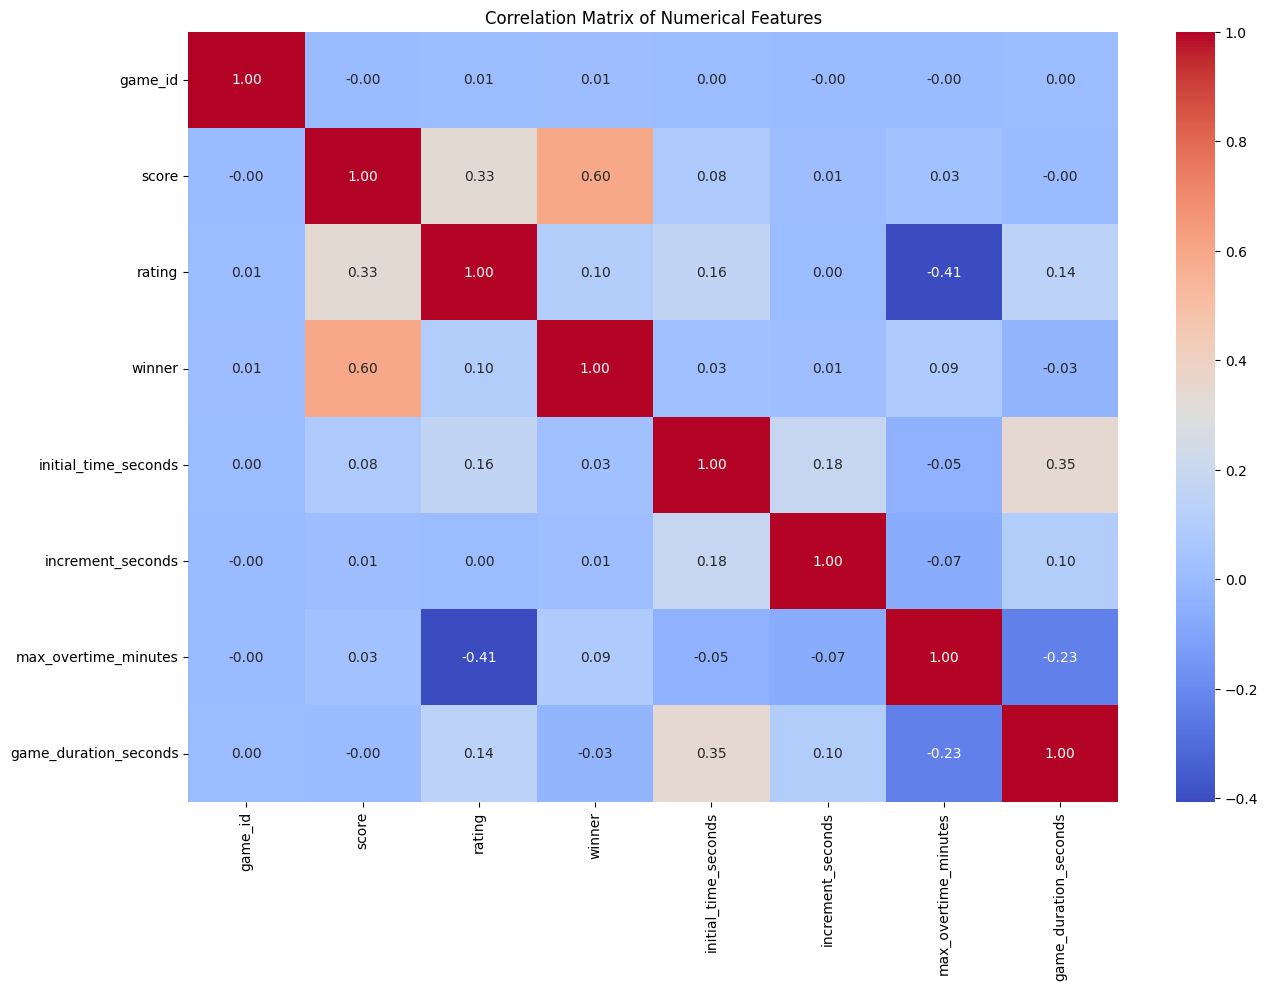

In [26]:
numerical_cols = human_train_df.select_dtypes(include=np.number).columns
corr_matrix = human_train_df[numerical_cols].corr()

plt.figure(figsize=(15, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

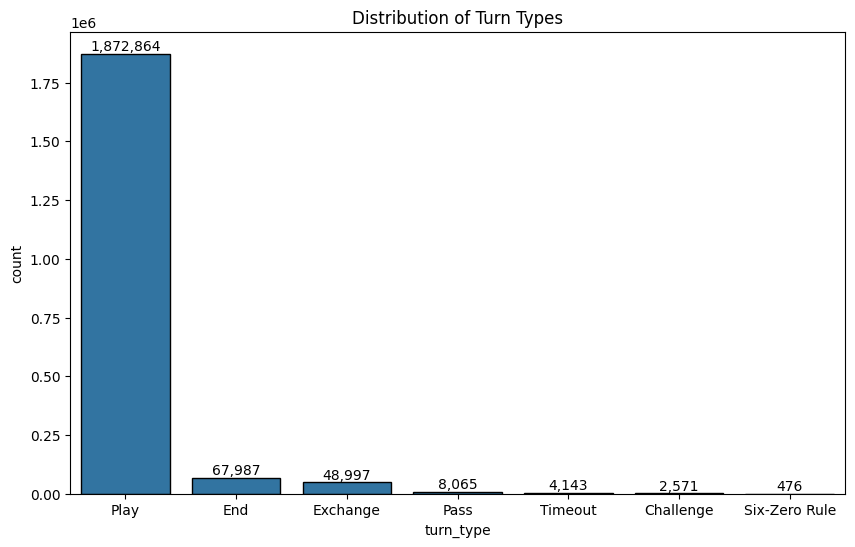

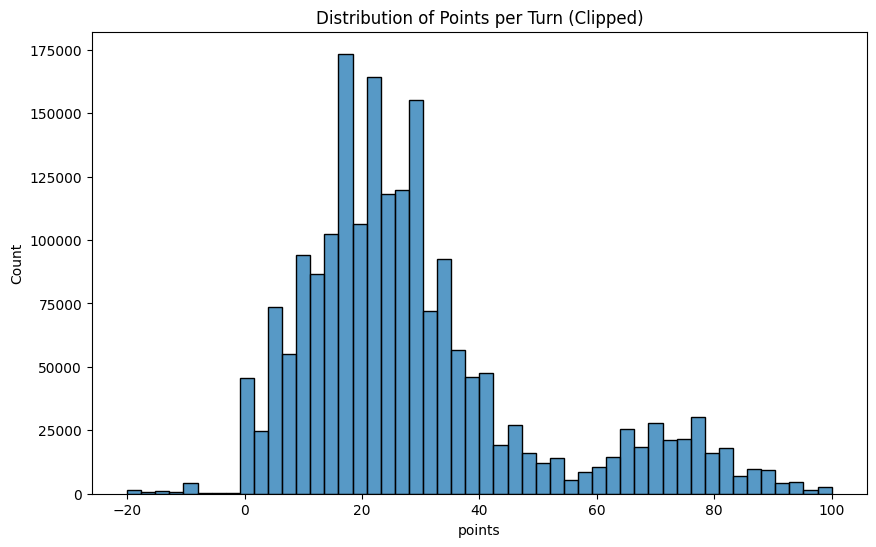

In [27]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=turns_df, x='turn_type', edgecolor='black')
plt.title('Distribution of Turn Types')

for container in ax.containers:
    labels = [f"{int(v.get_height()):,}" for v in container]
    ax.bar_label(container, labels=labels)
plt.show()

# What is the distribution of points per turn?
plt.figure(figsize=(10, 6))
sns.histplot(turns_df[turns_df['points'].between(-20,100)]['points'], bins=50)
plt.title('Distribution of Points per Turn (Clipped)')
plt.show()

Average rating for players against BetterBot (CASUAL): 1649.10
Average rating for players against BetterBot (RATED): 1792.96
Average rating for players against STEEBot (CASUAL): 1765.85
Average rating for players against STEEBot (RATED): 1886.47
Average rating for players against HastyBot (CASUAL): 1557.85
Average rating for players against HastyBot (RATED): 1912.18


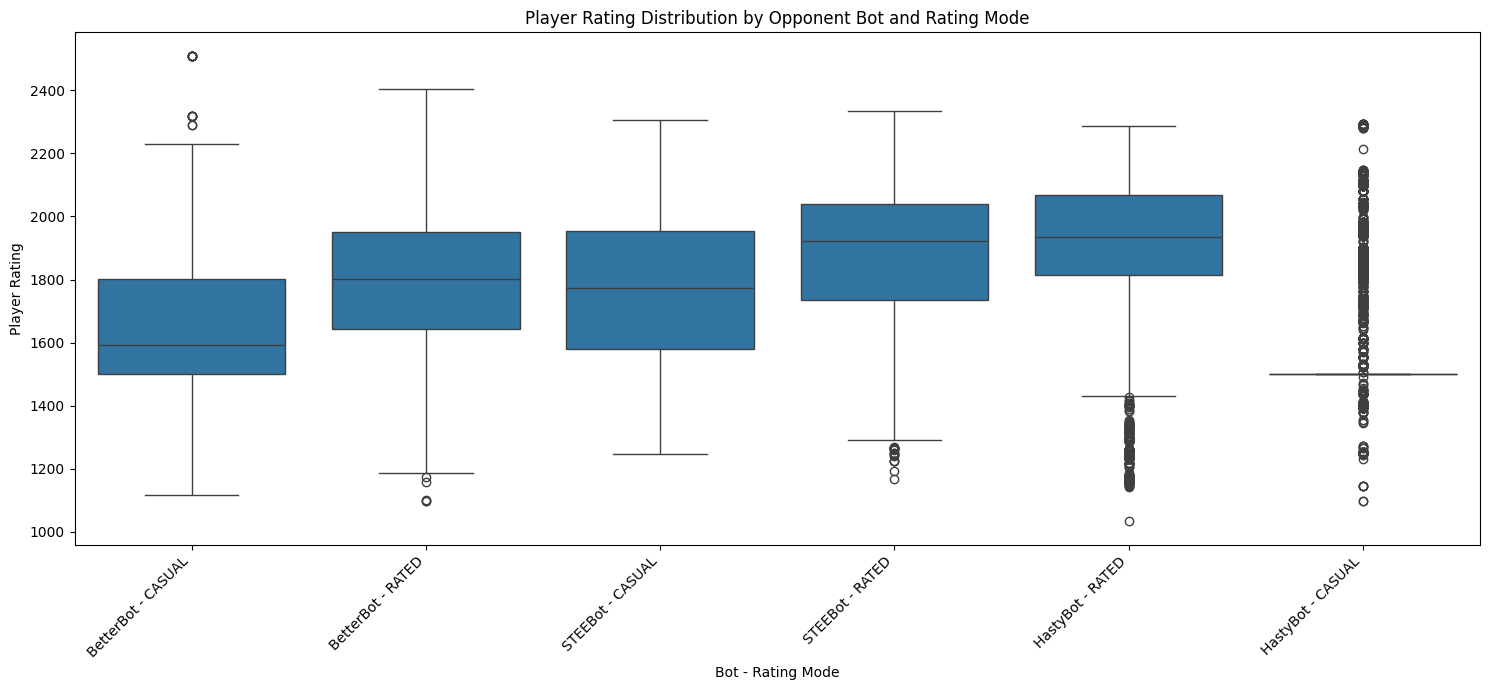

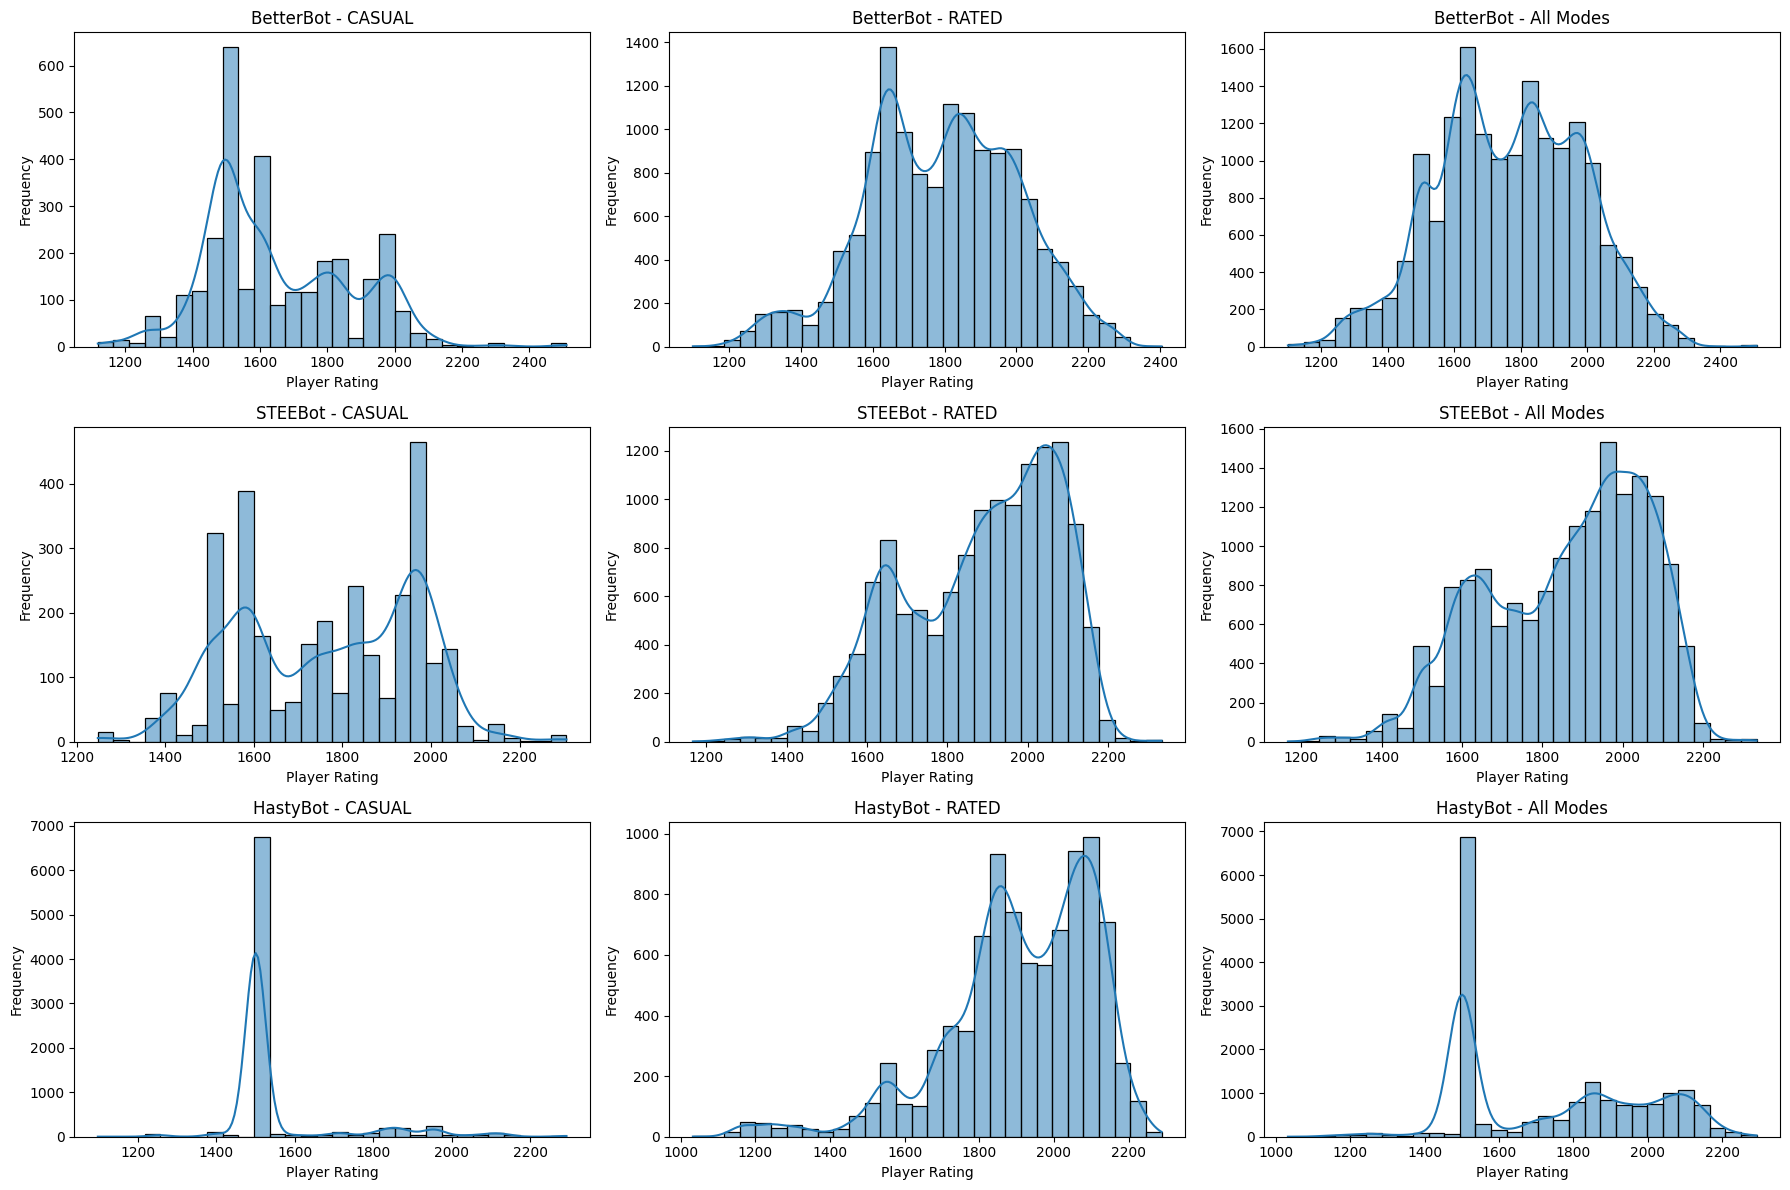

In [28]:
bot_rows = train_merged_df[train_merged_df['nickname'].isin(bots)]

bot_map = bot_rows.set_index('game_id')['nickname']
human_train_df = human_train_df.copy()
human_train_df.loc[:, 'opponent_bot'] = human_train_df['game_id'].map(bot_map)

# Create combined feature for bot and rating mode
human_train_df.loc[:, 'bot_rating_mode'] = human_train_df['opponent_bot'] + ' - ' + human_train_df['rating_mode']

# Print average ratings
for bot in bots:
    for mode in human_train_df['rating_mode'].unique():
        mask = (human_train_df['opponent_bot'] == bot) & (human_train_df['rating_mode'] == mode)
        avg_rating = human_train_df.loc[mask, 'rating'].mean()
        print(f'Average rating for players against {bot} ({mode}): {avg_rating:.2f}')

# Create boxplot with 6 boxes
plt.figure(figsize=(15, 7))
sns.boxplot(data=human_train_df, x='bot_rating_mode', y='rating')
plt.title('Player Rating Distribution by Opponent Bot and Rating Mode')
plt.xlabel('Bot - Rating Mode')
plt.ylabel('Player Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(18, 12), sharey=False)

for i, bot in enumerate(bots):
    for j, mode in enumerate(human_train_df['rating_mode'].unique()):
        ax = axes[i, j]
        mask = (human_train_df['opponent_bot'] == bot) & (human_train_df['rating_mode'] == mode)
        bot_mode_data = human_train_df[mask]
        
        sns.histplot(bot_mode_data['rating'], bins=30, kde=True, ax=ax)
        ax.set_title(f'{bot} - {mode}')
        ax.set_xlabel('Player Rating')
        ax.set_ylabel('Frequency')
    
    # Add histogram for all rating modes combined
    ax = axes[i, 2]
    bot_data = human_train_df[human_train_df['opponent_bot'] == bot]
    sns.histplot(bot_data['rating'], bins=30, kde=True, ax=ax)
    ax.set_title(f'{bot} - All Modes')
    ax.set_xlabel('Player Rating')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

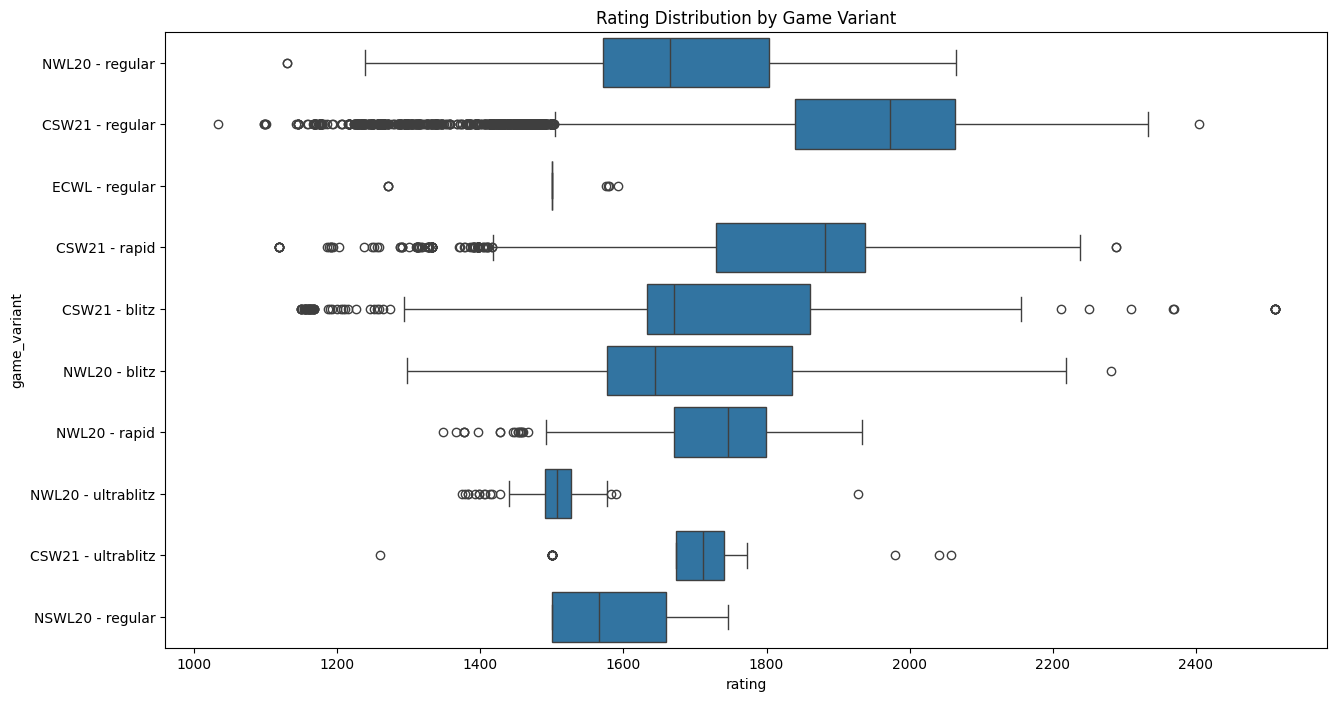

In [29]:
human_train_df = human_train_df.copy()
human_train_df.loc[:, 'game_variant'] = human_train_df['lexicon'] + ' - ' + human_train_df['time_control_name']

plt.figure(figsize=(15, 8))
sns.boxplot(data=human_train_df, x='rating', y='game_variant')
plt.title('Rating Distribution by Game Variant')
plt.show()

## Hypotheses to Explore

### 1. players with higher ratings tend to achieve higher final scores and higher average points per turn. 

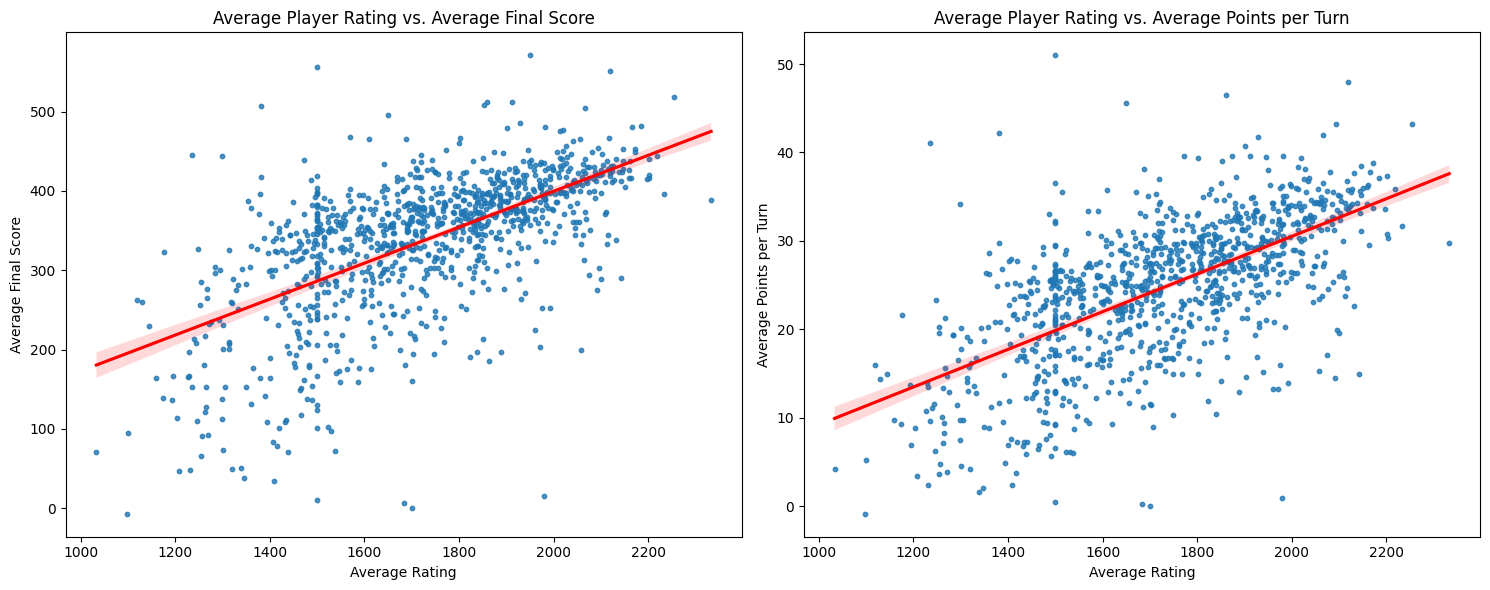

In [30]:
avg_points_per_player = (
    turns_df
    .groupby(['game_id', 'nickname'], as_index=False)['points']
    .mean()
    .rename(columns={'points': 'avg_points'})
)
avg_points_per_player_per_game = avg_points_per_player[~avg_points_per_player['nickname'].isin(bots)]

avg_points_per_player_per_game = avg_points_per_player_per_game.merge(
    human_train_df[['game_id', 'nickname', 'score', 'rating']],
    on=['game_id', 'nickname'],
    how='right'
)
avg_per_player = avg_points_per_player_per_game.groupby('nickname').agg({
    'avg_points': 'mean',
    'score': 'mean',
    'rating': 'mean'
}).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.regplot(data=avg_per_player, x='rating', y='score', ax=axes[0], scatter_kws={'s': 10}, line_kws={'color': 'red'})
axes[0].set_title('Average Player Rating vs. Average Final Score')
axes[0].set_xlabel('Average Rating')
axes[0].set_ylabel('Average Final Score')

sns.regplot(data=avg_per_player, x='rating', y='avg_points', ax=axes[1], scatter_kws={'s': 10}, line_kws={'color': 'red'})
axes[1].set_title('Average Player Rating vs. Average Points per Turn')
axes[1].set_xlabel('Average Rating')
axes[1].set_ylabel('Average Points per Turn')
plt.tight_layout()
plt.show()

In [31]:
bot_rows = train_merged_df[train_merged_df['nickname'].isin(bots)]
bot_map = bot_rows.set_index('game_id')['nickname']
human_train_df = human_train_df.copy()
human_train_df.loc[:, 'opponent_bot'] = human_train_df['game_id'].map(bot_map)


In [32]:
corr_score, p_score = stats.pearsonr(avg_per_player['rating'], avg_per_player['score'])
print(f"Correlation (Rating vs. Score): r={corr_score:.4f}, p-value={p_score:.4e}")

corr_avg_points, p_avg_points = stats.pearsonr(avg_per_player['rating'], avg_per_player['avg_points'])
print(f"Correlation (Rating vs. Avg. Points): r={corr_avg_points:.4f}, p-value={p_avg_points:.4e}")

Correlation (Rating vs. Score): r=0.6109, p-value=3.4065e-106
Correlation (Rating vs. Avg. Points): r=0.6252, p-value=1.4437e-112


The visual trends observed in the scatter plots are confirmed by the Pearson correlation. There is a strong, positive correlation between a player's Average Rating and their Average Final Score, with a coefficient ($r$) of 0.6109. An even stronger relationship was found between Average Rating and Average Points per Turn ($r = 0.6252$).
The p-value are basically 0, indicating that these results are highly statistically significant and are not due to random chance.

### 2. Higher-rated players are matched against more difficult bots.

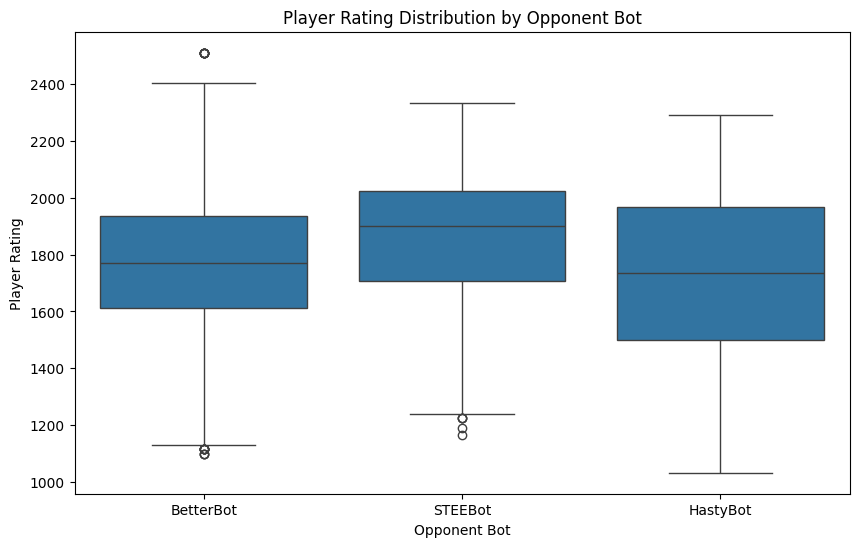

In [33]:
if 'opponent_bot' not in human_train_df.columns:
    bot_rows = train_merged_df[train_merged_df['nickname'].isin(bots)]
    bot_map = bot_rows.set_index('game_id')['nickname']
    human_train_df['opponent_bot'] = human_train_df['game_id'].map(bot_map)

# Plot the distribution
plt.figure(figsize=(10, 6))
sns.boxplot(data=human_train_df, x='opponent_bot', y='rating', order=['BetterBot', 'STEEBot', 'HastyBot'])
plt.title('Player Rating Distribution by Opponent Bot')
plt.xlabel('Opponent Bot')
plt.ylabel('Player Rating')
plt.show()


We can see that this hypothesis is not entirely accurate. While the rating of players matched against STEEBot are generally higher than those matched against BetterBot (which matches the hypothesis), players matched against HastyBot have "lower" distributions of ratings compared to those matched against STEEBot. 

This suggests that the relationship between player ratings and bot difficulty is not strictly linear, and other factors may be at play in the matchmaking process.

### 3. Do players with higher ratings tend to have more bingo plays (using all 7 tiles in a single turn)?

In [31]:
def add_bingo_proxy_feature(df_to_add, turns_df):
    """
    Calculates bingo counts using 'points > 50' as a proxy,
    which works for both train and test sets.
    """
    is_bingo = (turns_df['points'] > 50) & (turns_df['turn_type'] == 'Play')
    
    bingo_counts = (
        turns_df[is_bingo]
        .groupby(['game_id', 'nickname'], as_index=False)
        .size()
        .rename(columns={'size': 'bingo_count'})
    )
        
    df_to_add = df_to_add.copy()
    
    df_to_add = df_to_add.merge(
        bingo_counts, 
        on=['game_id', 'nickname'],
        how='left'
    )
    
    df_to_add['bingo_count'] = df_to_add['bingo_count'].fillna(0).astype(int)
    
    return df_to_add

human_train_df = add_bingo_proxy_feature(human_train_df, turns_df)

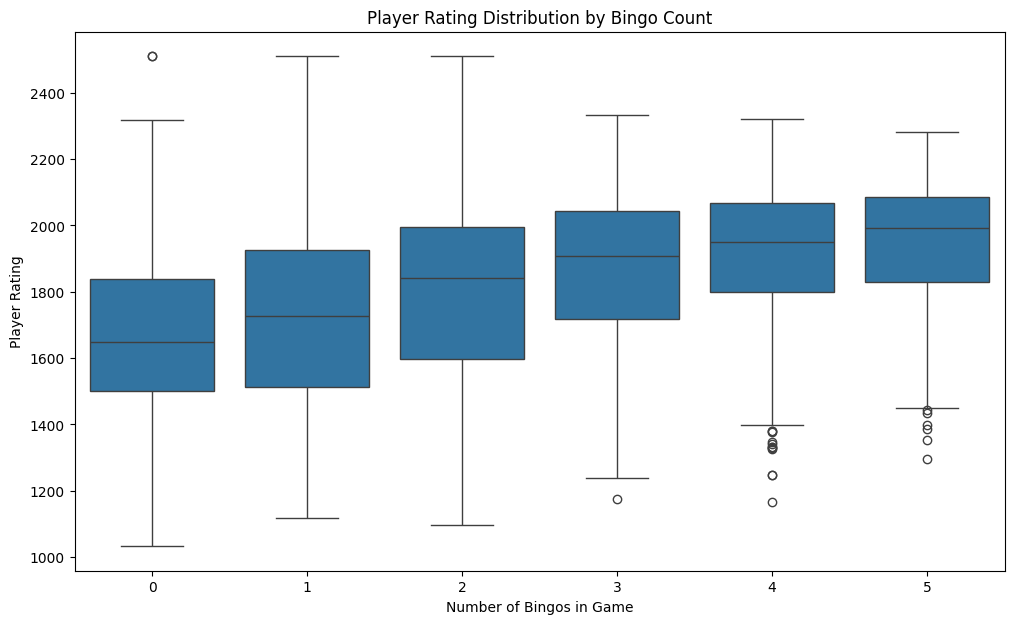

bingo_count
0     6761
1    14662
2    15657
3     9198
4     3243
5      733
6      142
7       12
8        2
Name: count, dtype: int64

In [32]:
plot_data = human_train_df[human_train_df['bingo_count'] < 6]

plt.figure(figsize=(12, 7))
sns.boxplot(data=plot_data, x='bingo_count', y='rating')
plt.title('Player Rating Distribution by Bingo Count')
plt.xlabel('Number of Bingos in Game')
plt.ylabel('Player Rating')
plt.show()

bingo_count_distribution = human_train_df['bingo_count'].value_counts().sort_index()
bingo_count_distribution

The boxplot clearly confirms the hypothesis that player rating is strongly correlated with bingo count. As the number of bingos played in a game increases, there is a noticeable upward trend in player median ratings, with tighter distribution. 

## Timestamp analysis

In [33]:
def add_timestamp_features(df, timestamp_col='created_at'):
    df_ret = df.copy()
    df_ret[timestamp_col] = pd.to_datetime(df[timestamp_col])
    df_ret['day_of_week'] = df_ret[timestamp_col].dt.day_name()
    df_ret['hour_of_day'] = df_ret[timestamp_col].dt.hour
    df_ret['is_weekend'] = df_ret['day_of_week'].isin(['Saturday', 'Sunday'])
    return df_ret
human_train_df = add_timestamp_features(human_train_df, 'created_at')

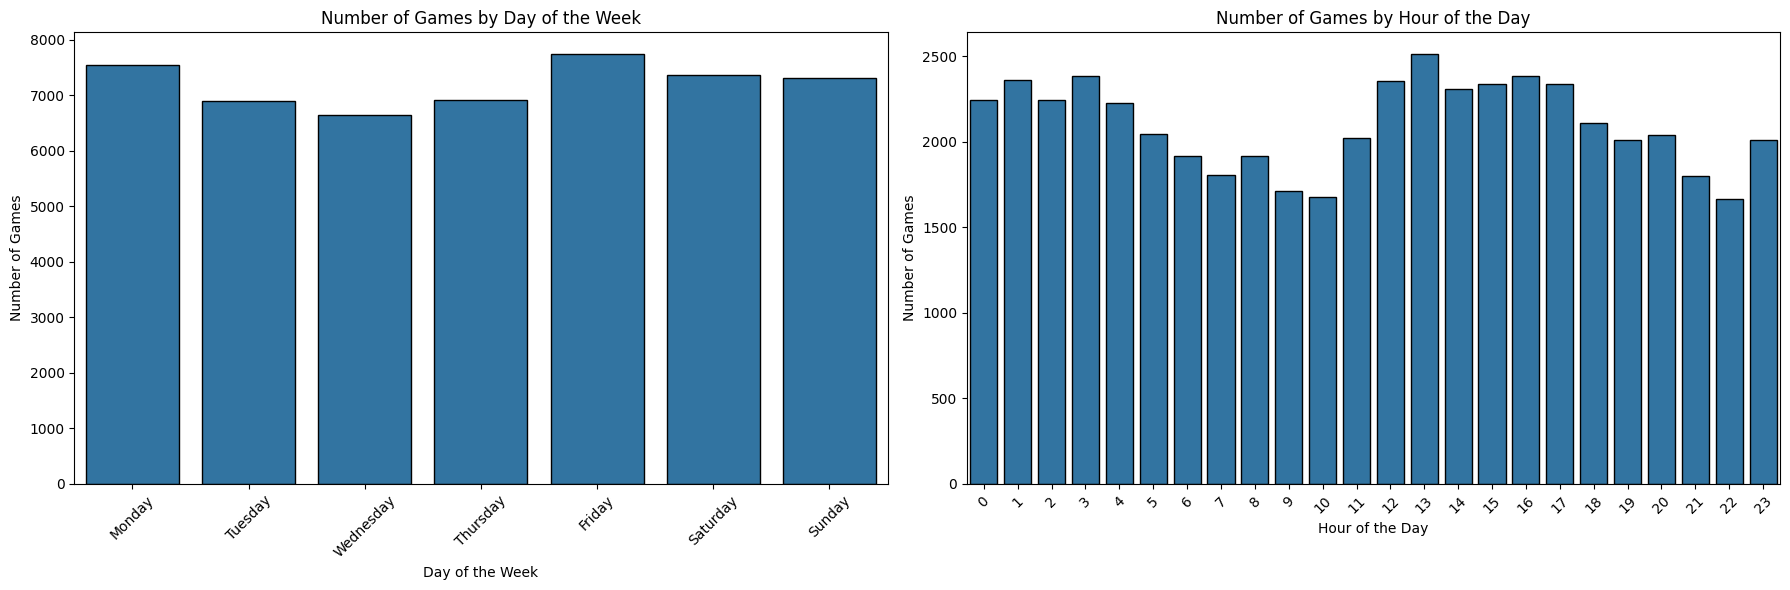

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=human_train_df, x='day_of_week', order=day_order, edgecolor='black', ax=axes[0])
axes[0].set_title('Number of Games by Day of the Week')
axes[0].set_xlabel('Day of the Week')
axes[0].set_ylabel('Number of Games')
axes[0].tick_params(axis='x', rotation=45)

sns.countplot(data=human_train_df, x='hour_of_day', edgecolor='black', ax=axes[1])
axes[1].set_title('Number of Games by Hour of the Day')
axes[1].set_xlabel('Hour of the Day')
axes[1].set_ylabel('Number of Games')
axes[1].set_xticks(range(0, 24))
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Do higher-rated players tend to play more on weekends compared to lower-rated players?

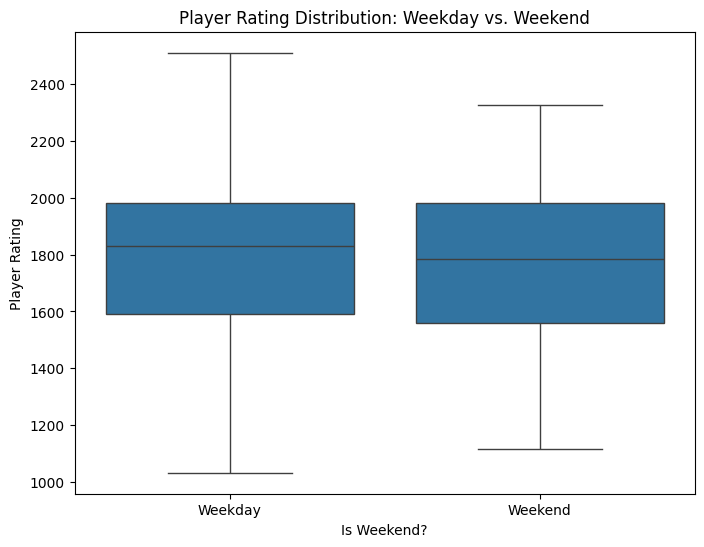

In [35]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=human_train_df, x='is_weekend', y='rating')
plt.title('Player Rating Distribution: Weekday vs. Weekend')
plt.xlabel('Is Weekend?')
plt.ylabel('Player Rating')
plt.xticks([0, 1], ['Weekday', 'Weekend'])
plt.show()

We can see that there is very subtle difference in the rating distributions between weekend and weekday games. The median ratings are quite similar, with weekend games having a slightly lower median rating. The whiskers of weekday games extend farther, indicating a wider range of ratings played on weekdays which makes sense to me at least. 

### Do higher-rated players tend to play more during certain hours of the day?

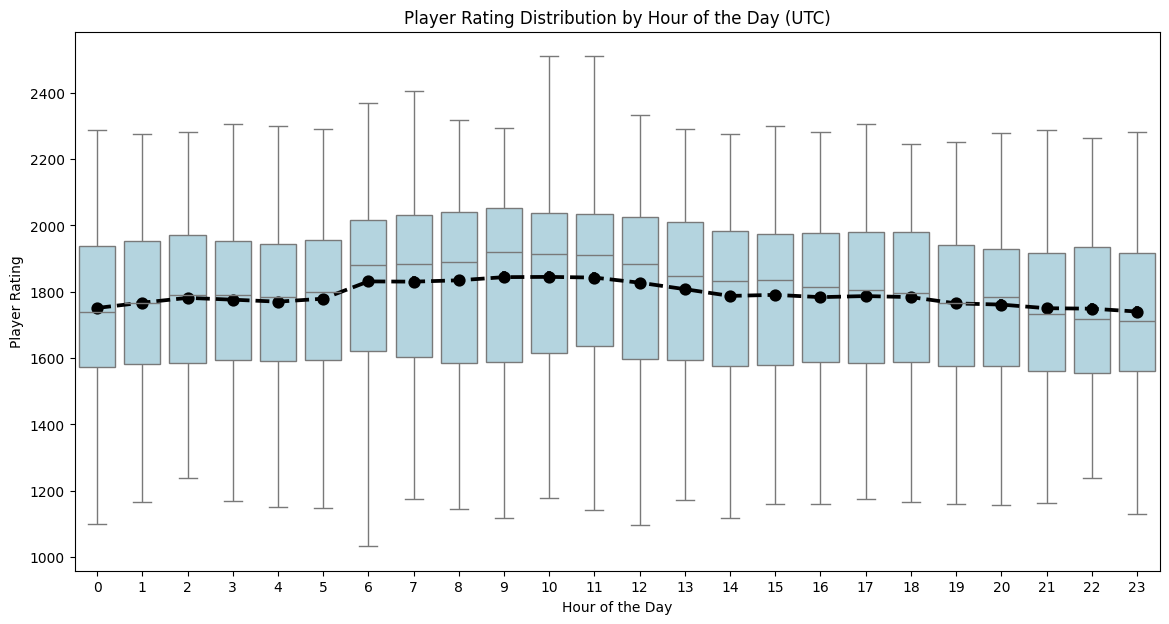

In [36]:
plt.figure(figsize=(14, 7))
sns.boxplot(data=human_train_df, x='hour_of_day', y='rating', color='lightblue')
# You can also overlay a pointplot to see the mean more clearly
sns.pointplot(data=human_train_df, x='hour_of_day', y='rating', color='black', linestyles="--")
plt.title('Player Rating Distribution by Hour of the Day (UTC)')
plt.xlabel('Hour of the Day')
plt.ylabel('Player Rating')
plt.show()

We can see that there is a clear trend where the mean rating (the black dotted line) rises from about 5:00, peaks between 8:00 and 12:00, and then gradually trends back down. This suggests that maybe higher-rated players tend to play more during the late morning to early afternoon hours.

### Do lower rated players tend go more into overtime? 

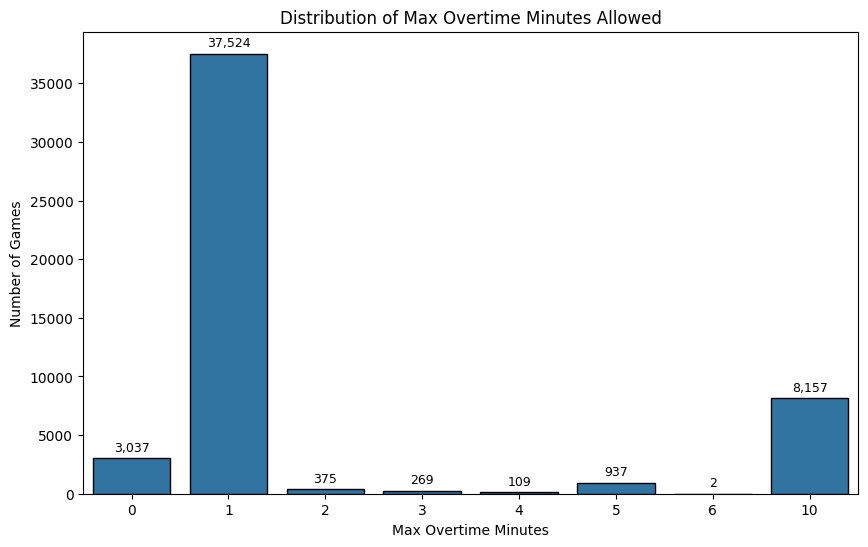

In [47]:
plt.figure(figsize=(10, 6))
sns.countplot(data=human_train_df, x='max_overtime_minutes', edgecolor='black')
plt.title('Distribution of Max Overtime Minutes Allowed')
plt.xlabel('Max Overtime Minutes')
plt.ylabel('Number of Games')

for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().annotate(f'{int(height):,}',
                xy=(p.get_x() + p.get_width() / 2, height),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)
plt.show()